# TE-292 — Aula 3: juntando dados de manutenção

| | |
|---|---|
| **Disciplina** | TE-292 — Ciência de Dados em Operação e Manutenção de Aeronaves |
| **Instituição** | Instituto Tecnológico de Aeronáutica (ITA) — AeroLogLab |
| **Professor** | Antonio Celio Pereira de Mesquita |
| **Aluno** | João Paulo Gomes de Oliveira |
| | |

## Etapa A2 — Consumo de peças por motivo de manutenção (versão revisada)

**Tempo previsto:** 45 minutos

Esta é uma revisão de `A_maint_part_cons.ipynb` feita após uma checagem de
qualidade da fonte. A etapa 1 (granularidade, esquema) é igual à versão
original. A partir da etapa 2 incorporamos cinco melhorias encontradas na
checagem:

1. **duplicatas exatas** na fonte não eram detectadas nem tratadas;
2. **quantidades negativas** ficavam escondidas dentro do diagnóstico de
   outliers, misturadas com consumo anormalmente alto;
3. o diagnóstico de outliers usava um **único limite (IQR) para todos os
   motivos**, mesmo eles tendo escalas de consumo muito diferentes;
4. a tabela final guardava **apenas a média** de consumo por motivo, perdendo
   o volume total e a frequência de eventos;
5. o anexo citava um cruzamento com `Asset_new_informations.csv` que nunca
   era executado.

Cada seção nova traz o diagnóstico, a decisão tomada e a justificativa —
sempre registrando o que foi feito, nunca alterando a fonte original.

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
%matplotlib inline

DATA_DIR = Path("dados_manutencao")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

source_path = DATA_DIR / "maintenance_part_consumption.csv"
consumption_raw = pd.read_csv(source_path)

print(f"Fonte: {source_path}")

print(f"Dimensão: {consumption_raw.shape[0]:,} linhas × {consumption_raw.shape[1]} colunas")
consumption_raw.head()

Fonte: dados_manutencao/maintenance_part_consumption.csv
Dimensão: 270,830 linhas × 5 colunas


,Asset,Time,Reason,Part,Quantity
0,A311482,0,R417,P361646,1
1,A174613,0,R707,P991287,1
2,A174613,0,R707,P169319,1
3,A060723,0,R193,P184448,0
4,A174613,0,R707,P097048,1


## 1. O que representa cada linha?

O termo **granularidade** indica o nível de detalhe dos dados — em outras
palavras, o que cada linha representa. Nesta tabela, uma linha representa um
evento de consumo: `ativo + instante + motivo + peça + quantidade`. Por isso
o mesmo `Asset` aparece várias vezes.

A coluna `Asset` é nossa **chave de integração**: será usada para relacionar
esta tabela com as demais fontes de manutenção.

In [15]:
column_summary = pd.DataFrame({
    "tipo": consumption_raw.dtypes.astype(str),
    "campos_vazios": consumption_raw.isna().sum(),
    "valores_diferentes": consumption_raw.nunique(dropna=True),
})

print("Resumo das colunas")
display(column_summary)

print(f"Ativos diferentes: {consumption_raw['Asset'].nunique():,}")
print(f"Motivos diferentes: {consumption_raw['Reason'].nunique():,}")
print(f"Peças diferentes: {consumption_raw['Part'].nunique():,}")

Resumo das colunas


,tipo,campos_vazios,valores_diferentes
Asset,str,0,1913
Time,int64,0,727
Reason,str,0,14
Part,str,0,3192
Quantity,int64,0,191


Ativos diferentes: 1,913
Motivos diferentes: 14
Peças diferentes: 3,192


## 2. Duplicatas exatas — um problema de qualidade escondido

A chave lógica de um evento de consumo é `(Asset, Time, Reason, Part)`: em
princípio, cada combinação dessas quatro colunas deveria descrever um único
evento. Duas situações merecem atenção:

- **duplicata exata:** a mesma linha (inclusive `Quantity`) aparece mais de
  uma vez — não acrescenta informação nova, é sinal de exportação ou junção
  duplicada;
- **conflito:** a mesma chave `(Asset, Time, Reason, Part)` aparece com
  `Quantity` **diferente** entre as linhas — aqui não sabemos qual valor é o
  correto, então a linha não deve ser descartada sem critério.

Vamos medir os dois casos antes de decidir o que fazer.

In [16]:
key_cols = ["Asset", "Time", "Reason", "Part"]

exact_duplicates = consumption_raw.duplicated()
print(f"Linhas totalmente duplicadas: {exact_duplicates.sum():,} "
      f"({exact_duplicates.mean():.2%} da fonte)")

group_sizes = consumption_raw.groupby(key_cols).size()
print("\nDistribuição do número de linhas por chave (Asset, Time, Reason, Part):")
print(group_sizes.value_counts().sort_index().head(10).to_string())
print("Repetições máximas para a mesma chave:", group_sizes.max())

distinct_quantities = consumption_raw.groupby(key_cols)["Quantity"].nunique()
conflicting_keys = distinct_quantities[distinct_quantities > 1]
print(f"\nChaves com Quantity conflitante (valores diferentes p/ mesma chave): "
      f"{len(conflicting_keys):,}")

Linhas totalmente duplicadas: 49,258 (18.19% da fonte)

Distribuição do número de linhas por chave (Asset, Time, Reason, Part):
1     203216
2      11873
3       1011
4        295
5        202
6        394
7         65
8         60
9         49
10       108
Repetições máximas para a mesma chave: 24

Chaves com Quantity conflitante (valores diferentes p/ mesma chave): 1,438


**Leitura do diagnóstico:** quase 1 em cada 5 linhas é duplicata exata, com
grupos repetidos até dezenas de vezes — inclusive uma concentração
suspeita em torno de 12 repetições, um padrão mais coerente com uma
exportação/carga duplicada do que com coincidência estatística. Já os casos
de conflito de quantidade (chave igual, valor diferente) são uma ordem de
grandeza mais raros — provavelmente correções reais, não erros de carga.

**Decisão desta etapa:**

- descartamos as duplicatas exatas com `drop_duplicates()`, pois uma cópia
  idêntica de uma linha não representa um segundo evento;
- **mantivemos** as linhas com quantidade conflitante — não temos como saber
  qual valor está correto — e as sinalizamos numa coluna `quantity_conflict`
  para que análises futuras (e o modelo preditivo da etapa C) possam tratá-las
  com cautela.

In [17]:
consumption = consumption_raw.drop_duplicates().copy()

conflict_flag = (
    consumption.groupby(key_cols)["Quantity"].transform("nunique") > 1
)
consumption["quantity_conflict"] = conflict_flag

print(f"Linhas antes da deduplicação: {len(consumption_raw):,}")
print(f"Linhas depois da deduplicação: {len(consumption):,} "
      f"(-{len(consumption_raw) - len(consumption):,})")
print(f"Linhas sinalizadas com quantity_conflict=True: "
      f"{consumption['quantity_conflict'].sum():,}")

consumption.head()

Linhas antes da deduplicação: 270,830
Linhas depois da deduplicação: 221,572 (-49,258)
Linhas sinalizadas com quantity_conflict=True: 2,900


,Asset,Time,Reason,Part,Quantity,quantity_conflict
0,A311482,0,R417,P361646,1,False
1,A174613,0,R707,P991287,1,False
2,A174613,0,R707,P169319,1,False
3,A060723,0,R193,P184448,0,False
4,A174613,0,R707,P097048,1,False


## 3. Valores muito altos (ou negativos) são erros?

Na versão original usamos o **intervalo interquartil (IQR)** para sinalizar
valores afastados da maioria (**outliers**), calculado sobre a coluna
`Quantity` inteira. Duas revisões:

- **quantidade negativa não é um outlier estatístico, é um valor
  fisicamente inválido** para um consumo de peças — deve ser tratada à parte,
  não diluída no percentual de outliers;
- **motivos diferentes têm escalas de consumo muito diferentes.** Um único
  limite global para todos os 14 motivos tende a marcar como "outlier"
  justamente os motivos que naturalmente consomem mais peças. Por isso o IQR
  deve ser calculado **por motivo (`Reason`)**.

Como antes: identificar não é remover. Nenhum registro é alterado nesta
etapa — apenas sinalizado.

In [18]:
is_negative = consumption["Quantity"] < 0
print(f"Linhas com Quantity negativa: {is_negative.sum()} "
      f"({is_negative.mean():.3%} da fonte já sem duplicatas)")
display(consumption.loc[is_negative, key_cols + ["Quantity"]])
print("Decisão: mantidas e sinalizadas em 'is_negative'; tratadas fora do "
      "diagnóstico de outliers por IQR, pois não são 'consumo alto', são "
      "valores fora do domínio esperado (quantidade >= 0).")

consumption["is_negative"] = is_negative

Linhas com Quantity negativa: 10 (0.005% da fonte já sem duplicatas)


,Asset,Time,Reason,Part,Quantity
72268,A217825,209,R193,P085348,-2
155111,A024432,444,R193,P573388,-4
164794,A452161,467,R446,P481975,-1
183249,A768609,516,R193,P169319,-3
184996,A156160,521,R193,P764767,-1
207910,A771588,578,R193,P002198,-5
226080,A384922,621,R565,P169319,-4
231637,A150144,635,R193,P034735,-1
233174,A563025,638,R565,P427071,-5
260508,A366762,708,R446,P476637,-15


Decisão: mantidas e sinalizadas em 'is_negative'; tratadas fora do diagnóstico de outliers por IQR, pois não são 'consumo alto', são valores fora do domínio esperado (quantidade >= 0).


In [19]:
def iqr_bounds(group, factor=1.5):
    q1, q3 = group.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({"lower": q1 - factor * iqr, "upper": q3 + factor * iqr})

non_negative = consumption.loc[~consumption["is_negative"]]

bounds_by_reason = (
    non_negative
    .groupby("Reason")["Quantity"]
    .apply(iqr_bounds)
    .unstack()
)

consumption = consumption.merge(
    bounds_by_reason, left_on="Reason", right_index=True, how="left"
)
consumption["outside_iqr_by_reason"] = (
    ~consumption["is_negative"]
    & ~consumption["Quantity"].between(consumption["lower"], consumption["upper"])
)

print("Limites diagnósticos de IQR por motivo:")
display(bounds_by_reason)

outlier_rate_by_reason = (
    consumption
    .groupby("Reason")["outside_iqr_by_reason"]
    .mean()
    .sort_values(ascending=False)
)
print("\nPercentual de registros fora do limite, por motivo:")
print(outlier_rate_by_reason.map(lambda x: f"{x:.2%}").to_string())

print(f"\nTotal fora do limite (excluindo negativos): "
      f"{consumption['outside_iqr_by_reason'].sum():,} "
      f"({consumption['outside_iqr_by_reason'].mean():.2%})")
print("Decisão desta etapa: manter os valores e registrar a ressalva "
      "(agora por motivo, e sem misturar negativos ao diagnóstico).")

Limites diagnósticos de IQR por motivo:


,lower,upper
Reason,,
R044,-0.5,3.5
R064,-0.5,3.5
R119,-0.5,3.5
R193,-0.5,3.5
R364,1.0,1.0
R396,-5.0,11.0
R417,-0.5,3.5
R446,1.0,1.0
R565,-0.5,3.5



Percentual de registros fora do limite, por motivo:
Reason
R364    27.82%
R446    26.23%
R783    24.97%
R565    23.41%
R707    21.96%
R417    19.89%
R606    19.87%
R119    16.99%
R064    14.63%
R044    14.36%
R193    12.70%
R396    10.00%
R575     5.86%
R782     0.00%

Total fora do limite (excluindo negativos): 46,338 (20.91%)
Decisão desta etapa: manter os valores e registrar a ressalva (agora por motivo, e sem misturar negativos ao diagnóstico).


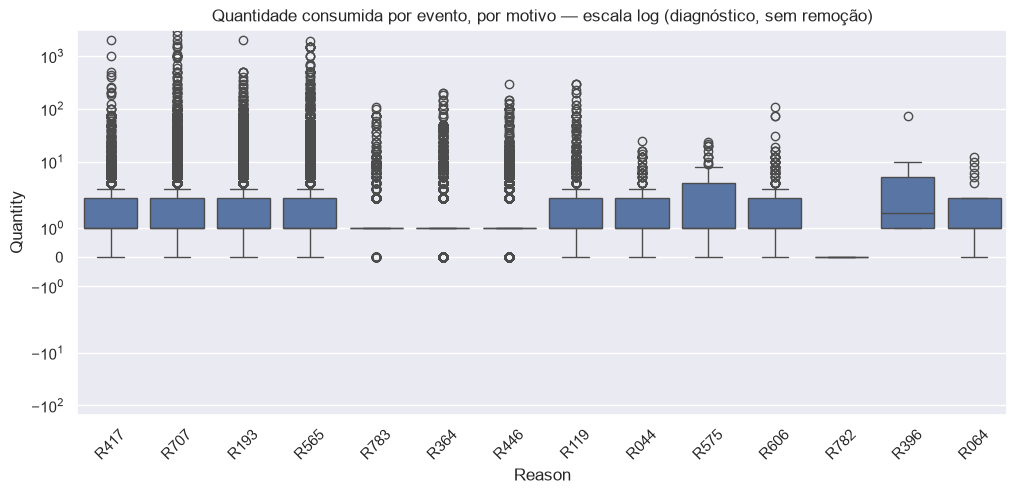

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(
    data=non_negative,
    x="Reason",
    y="Quantity",
    ax=ax,
)
ax.set_yscale("symlog")
ax.set_title("Quantidade consumida por evento, por motivo — escala log "
             "(diagnóstico, sem remoção)")
plt.xticks(rotation=45)
plt.show()

**Leitura do diagnóstico:** o percentual de "outliers" varia muito entre
motivos — um único limite global (como na versão original) sub- ou
super-sinalizaria motivos conforme sua escala natural de consumo. O gráfico
em escala logarítmica evidencia essas escalas distintas lado a lado.

> Pausa para discussão: que informação adicional seria necessária antes de
> limitar ou excluir uma quantidade elevada de um motivo específico?

## 4. Zeros: ausência de consumo ou motivo sem peça associada?

`Quantity = 0` é diferente de uma célula vazia: a linha existe, o evento foi
registrado, mas nenhuma peça foi de fato consumida. Antes de tratar isso como
"dado estranho" a ser descartado, vale checar se algum motivo é
sistematicamente assim — o que mudaria a interpretação de zero de "erro"
para "categoria válida" (por exemplo, uma intervenção sem troca de peça,
como uma inspeção).

In [21]:
zero_rate_by_reason = (
    consumption
    .groupby("Reason")["Quantity"]
    .apply(lambda s: (s == 0).mean())
    .sort_values(ascending=False)
)

print("Percentual de linhas com Quantity = 0, por motivo:")
print(zero_rate_by_reason.map(lambda x: f"{x:.2%}").to_string())

all_zero_reasons = zero_rate_by_reason[zero_rate_by_reason == 1.0].index.tolist()
print(f"\nMotivos em que TODO evento tem Quantity = 0: {all_zero_reasons}")

Percentual de linhas com Quantity = 0, por motivo:
Reason
R782    100.00%
R606      9.43%
R119      6.53%
R575      3.60%
R364      2.86%
R446      2.67%
R064      2.44%
R193      2.34%
R783      2.28%
R565      2.12%
R044      1.86%
R417      1.50%
R707      1.28%
R396      0.00%

Motivos em que TODO evento tem Quantity = 0: ['R782']


**Leitura do diagnóstico:** ao menos um motivo é composto inteiramente por
`Quantity = 0` — ou seja, para esse motivo o zero não é ruído, é a regra.
Isso reforça por que a etapa 3 calculou o IQR por motivo em vez de global, e
por que zeros não devem ser removidos ou imputados sem essa checagem.

**Decisão desta etapa:** manter os zeros como estão; ao agregar por motivo na
próxima seção, isso ficará explícito em `n_events` (que continuará contando o
evento) separado de `qty_sum` (que naturalmente será baixo ou zero para esses
motivos).

## 5. De várias linhas para uma linha por ativo — múltiplas métricas, não só a média

A tabela atual está no **formato longo (`long`)**. Para juntá-la aos dados de
uso e falha (etapas B e C), criaremos o **formato largo (`wide`)**: um ativo
por linha, um motivo por coluna.

Na versão original calculamos apenas a **média** de `Quantity` por
`(Asset, Reason)`. Isso esconde informação importante: dois ativos com a
mesma média podem ter passado por números de eventos e volumes totais muito
diferentes. Por isso, para cada `(Asset, Reason)` calcularemos quatro
métricas complementares:

- `qty_sum`: volume total consumido — aproxima a **severidade** acumulada;
- `qty_mean`: média por evento — comparável à versão original;
- `n_events`: número de eventos de consumo — a **frequência**;
- `n_parts`: número de peças distintas usadas — a **diversidade** de peças.

Células vazias continuam significando "não há consumo registrado para esse
motivo", não "consumo igual a zero".

In [22]:
metrics = {
    "qty_sum": ("Quantity", "sum"),
    "qty_mean": ("Quantity", "mean"),
    "n_events": ("Quantity", "size"),
    "n_parts": ("Part", "nunique"),
}

wide_tables = {}
for metric_name, (value_col, agg) in metrics.items():
    table = (
        consumption
        .pivot_table(index="Asset", columns="Reason", values=value_col, aggfunc=agg)
        .sort_index(axis=1)
    )
    table.columns = [f"{reason}_{metric_name}" for reason in table.columns]
    wide_tables[metric_name] = table

consumption_by_reason = pd.concat(wide_tables.values(), axis=1).reset_index()

assert consumption_by_reason["Asset"].is_unique

output_path = OUTPUT_DIR / "maintenance_part_consumption_by_reason_v2.csv"
consumption_by_reason.to_csv(output_path, index=False)

print(f"Tabela derivada: {consumption_by_reason.shape[0]:,} ativos × "
      f"{consumption_by_reason.shape[1] - 1} colunas "
      f"(14 motivos × 4 métricas)")
print(f"Salva em: {output_path}")
consumption_by_reason.filter(regex="^Asset$|^R417_|^R782_").head()

Tabela derivada: 1,913 ativos × 56 colunas (14 motivos × 4 métricas)
Salva em: output/maintenance_part_consumption_by_reason_v2.csv


,Asset,R417_qty_sum,R782_qty_sum,R417_qty_mean,R782_qty_mean,R417_n_events,R782_n_events,R417_n_parts,R782_n_parts
0,A000204,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A000270,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A000463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A000495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A001201,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Nota de compatibilidade:** este arquivo é salvo como
`maintenance_part_consumption_by_reason_v2.csv`, e não sobrescreve o arquivo
original consumido pela etapa B (`maintenance_part_consumption_by_reason.csv`).
A etapa B faz um `merge` genérico por `Asset` e não depende dos nomes exatos
das colunas de motivo, então adotar esta versão mais rica exigiria apenas
trocar o nome do arquivo lido em B — não uma reescrita do notebook.

## 6. Validação cruzada com `Asset_new_informations.csv`

O anexo da versão original citava um cruzamento com
`Asset_new_informations.csv` que nunca chegava a ser executado. Esse arquivo
traz, para 80 ativos, colunas como `R417_Quantity_sum` — ou seja, alguém já
calculou (por algum processo externo) o volume total consumido por motivo
para esses ativos. É uma oportunidade de checar se nossa soma bate com uma
fonte independente.

In [23]:
new_info_path = DATA_DIR / "Asset_new_informations.csv"
new_info = pd.read_csv(new_info_path)

print(f"Fonte: {new_info_path}")
print(f"Dimensão: {new_info.shape[0]:,} linhas × {new_info.shape[1]} colunas")
print(f"Ativos em comum com a tabela de consumo: "
      f"{new_info['Asset'].isin(consumption_by_reason['Asset']).sum()} / {len(new_info)}")

sum_columns = [c for c in new_info.columns if c.endswith("_Quantity_sum")]
comparison_rows = []
for col in sum_columns:
    reason = col.replace("_Quantity_sum", "")
    our_col = f"{reason}_qty_sum"
    if our_col not in consumption_by_reason.columns:
        continue
    merged = new_info[["Asset", col]].merge(
        consumption_by_reason[["Asset", our_col]], on="Asset", how="left"
    ).fillna(0)
    exact_match_rate = (merged[col] == merged[our_col]).mean()
    correlation = merged[col].corr(merged[our_col])
    comparison_rows.append({
        "Reason": reason,
        "correspondencia_exata": exact_match_rate,
        "correlacao": correlation,
    })

comparison = pd.DataFrame(comparison_rows).sort_values("correlacao", ascending=False)
display(comparison)

Fonte: dados_manutencao/Asset_new_informations.csv
Dimensão: 80 linhas × 18 colunas
Ativos em comum com a tabela de consumo: 80 / 80


/Users/joao/Documents/Documentos - MacBook Pro de Joao/ITA/code/ita_cdoma/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/joao/Documents/Documentos - MacBook Pro de Joao/ITA/code/ita_cdoma/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Reason,correspondencia_exata,correlacao
8,R044,1.0000,1.000000
9,R575,1.0000,1.000000
10,R606,0.9750,0.999999
3,R565,0.3250,0.963569
2,R193,0.1750,0.864224
5,R364,0.6375,0.861959
4,R783,0.8875,0.858266
0,R417,0.7375,0.721978
6,R446,0.5750,0.720015
7,R119,0.9625,0.647603


**Leitura do diagnóstico:** a correspondência exata é rara (varia de 2,5% a
100% conforme o motivo), como esperado para fontes com proveniência diferente.
Mas a **correlação** conta uma história mais clara: para `R044`, `R575` e
`R606` ela é praticamente perfeita (~1,00) — fortíssima evidência de que
descrevem o mesmo fenômeno, ainda que em escalas ou janelas diferentes. Para
motivos como `R707` (0,55) e `R193` (0,86) a relação é mais fraca — pode
indicar janelas de tempo bem diferentes entre as fontes, ou maior ruído
naquele motivo. Já `R064`, `R396` e `R782` retornam correlação indefinida
(`NaN`): nossa soma para esses motivos não varia entre ativos (é
constante, geralmente zero — lembra o achado da seção 4), o que torna a
correlação matematicamente indefinida (divisão por desvio-padrão zero), não
um erro de cálculo.

**Decisão desta etapa:** tratar `Asset_new_informations.csv` como uma fonte
independente para checagem de consistência relativa (correlação), não como
gabarito de igualdade exata — e usar os motivos de correlação baixa como
prioridade para investigar a proveniência dos dados antes de confiar neles
num modelo preditivo.

## Ponto de verificação da etapa A2

- **Dado primário:** `maintenance_part_consumption.csv`, recebido como fonte;
- **Transformações aplicadas, em ordem:**
  1. remoção de duplicatas exatas (`drop_duplicates`), com conflitos de
     quantidade sinalizados (não removidos) em `quantity_conflict`;
  2. sinalização de quantidades negativas (`is_negative`), tratadas fora do
     diagnóstico de outliers;
  3. diagnóstico de outliers por IQR calculado **por motivo**
     (`outside_iqr_by_reason`), não globalmente;
  4. checagem do padrão de zeros por motivo;
  5. agregação para uma linha por ativo com quatro métricas por motivo
     (`qty_sum`, `qty_mean`, `n_events`, `n_parts`) em vez de apenas a média;
  6. validação cruzada de consistência com `Asset_new_informations.csv`.
- **Dado derivado:** `output/maintenance_part_consumption_by_reason_v2.csv`;
- **Coluna de ligação:** `Asset`, com um único valor por linha.

**Antes de seguir para B:** com quatro métricas por motivo em vez de uma,
quais delas você usaria para prever falha — volume total, frequência,
diversidade de peças, ou uma combinação?

## Anexo — Falhas nos registros de manutenção (`maintenance_failures.csv`)

Repetimos aqui as checagens de qualidade da etapa 1, agora cruzando a chave
`Asset` com `maintenance_part_consumption.csv` (já sem duplicatas exatas).

In [24]:
failures_path = DATA_DIR / "maintenance_failures.csv"
failures = pd.read_csv(failures_path)

print(f"Fonte: {failures_path}")
print(f"Dimensão: {failures.shape[0]:,} linhas × {failures.shape[1]} colunas\n")

failures_summary = pd.DataFrame({
    "tipo": failures.dtypes.astype(str),
    "campos_vazios": failures.isna().sum(),
    "valores_diferentes": failures.nunique(dropna=True),
})
print("Resumo das colunas")
display(failures_summary)

print(f"Ativos repetidos: {failures['Asset'].duplicated().sum()}")
print(f"Valores fora de {{0, 1}} em failure_bin: "
      f"{(~failures['failure_bin'].isin([0, 1])).sum()}")
print("\nDistribuição de failure_bin")
print(failures["failure_bin"].value_counts().to_string())
print(f"Taxa de falha: {failures['failure_bin'].mean():.2%}")

Fonte: dados_manutencao/maintenance_failures.csv
Dimensão: 1,805 linhas × 2 colunas

Resumo das colunas


,tipo,campos_vazios,valores_diferentes
Asset,str,0,1805
failure_bin,int64,0,2


Ativos repetidos: 0
Valores fora de {0, 1} em failure_bin: 0

Distribuição de failure_bin
failure_bin
0    1357
1     448
Taxa de falha: 24.82%


O arquivo em si está limpo: sem `Asset` repetido, sem campo vazio, e
`failure_bin` só assume 0 ou 1. O problema aparece quando cruzamos essa chave
com as outras fontes.

In [25]:
consumption_assets = set(consumption["Asset"])
failure_assets = set(failures["Asset"])

only_in_consumption = consumption_assets - failure_assets
only_in_failures = failure_assets - consumption_assets

print(f"Ativos em consumo sem registro de falha:  {len(only_in_consumption):,}")
print(f"Ativos com falha sem evento de consumo:   {len(only_in_failures):,}")

lost_events = consumption[consumption["Asset"].isin(only_in_consumption)]
print(f"\nEventos de consumo 'órfãos' (sem resposta de falha conhecida): "
      f"{len(lost_events):,} linhas, {lost_events['Asset'].nunique()} ativos")
print("Motivos mais comuns nesses eventos órfãos:")
print(lost_events["Reason"].value_counts().head())

print(
    "\nDecisão: os 108 ativos órfãos serão mantidos na tabela de consumo "
    "(não descartamos dado de origem), mas ao chegar à etapa B — que faz "
    "left join a partir de usage_data — eles resultarão em failure_bin "
    "vazio e devem ser excluídos apenas do treino do modelo supervisionado "
    "da etapa C, nunca das estatísticas descritivas de consumo."
)

Ativos em consumo sem registro de falha:  108
Ativos com falha sem evento de consumo:   0

Eventos de consumo 'órfãos' (sem resposta de falha conhecida): 5,413 linhas, 108 ativos
Motivos mais comuns nesses eventos órfãos:
Reason
R707    3649
R565     864
R446     315
R193     242
R364     152
Name: count, dtype: int64

Decisão: os 108 ativos órfãos serão mantidos na tabela de consumo (não descartamos dado de origem), mas ao chegar à etapa B — que faz left join a partir de usage_data — eles resultarão em failure_bin vazio e devem ser excluídos apenas do treino do modelo supervisionado da etapa C, nunca das estatísticas descritivas de consumo.
